# Chapitre 10 - Cours 2 : fonctions de perte, robustesse et gradient boosting

Ce notebook couvre les sections 10.6 à 10.12 du livre :

1. les **fonctions de perte** pour la classification et la régression, et leur
   **robustesse** (figures 10.4 et 10.5) ;
2. le **boosting d'arbres** (section 10.9) ;
3. le **gradient boosting** (algorithme 10.3, « MART ») et les gradients usuels (tableau 10.2) ;
4. la **taille des arbres** et les interactions (figures 10.9 et 10.10) ;
5. la **régularisation** : rétrécissement (*shrinkage*, figure 10.11) et sous-échantillonnage
   (figure 10.12).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch10_boosting import (
    AdaBoostM1, GradientBoosting, RegressionTree, simulate_nested_spheres,
    loss_misclassification, loss_exponential, loss_binomial_deviance,
    loss_squared_margin, loss_hinge, loss_huber)

## 1. Pertes pour la classification : la marge

Avec $y \in \{-1,+1\}$ et une fonction réelle $f$ dont le signe donne la classe prédite,
la quantité clé est la **marge** $y\,f(x)$ :

- $y f(x) > 0$ : observation bien classée ; plus la marge est grande, plus on est « sûr » ;
- $y f(x) < 0$ : observation mal classée.

Une bonne perte de classification doit pénaliser les marges négatives bien plus que les
marges positives (déjà correctes). Toutes les pertes ci-dessous s'écrivent comme une
fonction de la marge seule.

Les pertes de la figure 10.4 (chacune normalisée pour passer par le point $(0,1)$) :

| perte | expression en fonction de $m = yf$ |
|---|---|
| mauvaise classification | $I(m < 0)$ |
| exponentielle (10.8) | $e^{-m}$ |
| déviance binomiale (10.18) | $\log(1+e^{-2m}) / \log 2$ |
| quadratique | $(y-f)^2 = (1-m)^2$ (car $y^2=1$) |
| « support vector » (chap. 12) | $(1-m)_+ = \max(0, 1-m)$ |

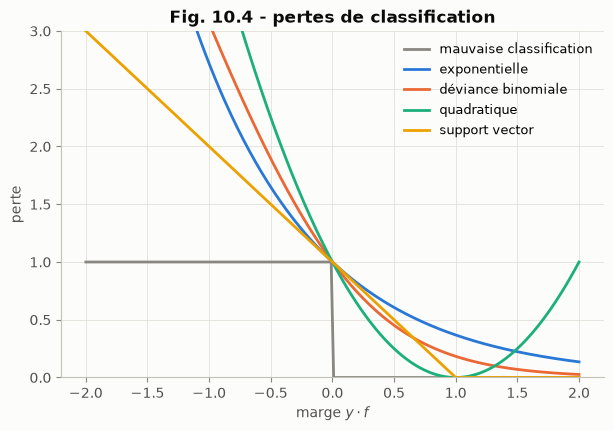

In [2]:
m = np.linspace(-2, 2, 401)
plt.figure(figsize=(7, 4.5))
plt.plot(m, loss_misclassification(m), color=GRAY, label="mauvaise classification")
plt.plot(m, loss_exponential(m), color=COLORS[0], label="exponentielle")
plt.plot(m, loss_binomial_deviance(m), color=COLORS[1], label="déviance binomiale")
plt.plot(m, loss_squared_margin(m), color=COLORS[2], label="quadratique")
plt.plot(m, loss_hinge(m), color=COLORS[3], label="support vector")
plt.ylim(0, 3)
plt.title("Fig. 10.4 - pertes de classification")
plt.xlabel("marge $y\\cdot f$")
plt.ylabel("perte")
plt.legend()
plt.show()

Lecture de la figure :

- exponentielle et déviance sont des approximations **continues et décroissantes** de la
  perte 0-1 ; pour des marges très négatives, la déviance croît **linéairement** (comme $-2m/\log 2$)
  alors que l'exponentielle croît **exponentiellement** ;
- la perte quadratique n'est pas monotone : au-delà de $m=1$ elle **augmente** et pénalise
  donc des observations très bien classées. C'est pourquoi elle convient mal à la classification ;
- la perte « support vector » est nulle dès que $m \ge 1$ (cf. chapitre 12).

### Minimiseurs en population

Pour $p = P(Y=1\mid x)$, on a vu au cours 1 que l'exponentielle et la déviance ont le même
minimiseur $f^*(x) = \frac12 \log\frac{p}{1-p}$. Pour la perte quadratique :

$$f^*(x) = \arg\min_f E_{Y\mid x}(Y - f)^2 = E(Y\mid x) = 2p - 1 \qquad \text{(éq. (10.19))},$$

car l'espérance conditionnelle minimise l'erreur quadratique et
$E(Y\mid x) = 1\cdot p + (-1)(1-p)$. Les trois cibles ont le **signe** de $p - 1/2$ :
en population, elles conduisent toutes à la règle de Bayes.

### Robustesse : l'influence des marges très négatives

Dans un algorithme de descente, l'influence d'une observation est mesurée par la
**dérivée** de la perte par rapport à $f$ (ou à la marge). Comparons
$\big|\partial L/\partial m\big|$ :

- exponentielle : $|{-e^{-m}}| = e^{-m}$, qui explose quand $m \to -\infty$ ;
- déviance (non normalisée) : $\big|{-2e^{-2m}/(1+e^{-2m})}\big| = 2/(1+e^{2m}) \le 2$, bornée.

Une observation **mal étiquetée** finit avec une marge très négative ; avec la perte
exponentielle elle reçoit un poids énorme, avec la déviance son poids reste borné.

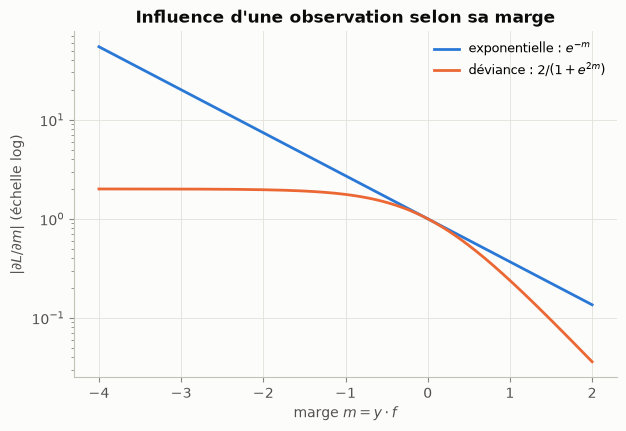

In [3]:
mm = np.linspace(-4, 2, 300)
plt.figure(figsize=(7, 4.5))
plt.plot(mm, np.exp(-mm), color=COLORS[0], label="exponentielle : $e^{-m}$")
plt.plot(mm, 2 / (1 + np.exp(2 * mm)), color=COLORS[1], label="déviance : $2/(1+e^{2m})$")
plt.yscale("log")
plt.title("Influence d'une observation selon sa marge")
plt.xlabel("marge $m = y\\cdot f$")
plt.ylabel("$|\\partial L / \\partial m|$ (échelle log)")
plt.legend()
plt.show()

### Un calcul simple : poids relatif d'une observation très mal classée

Comparons l'influence d'une observation de marge $m$ à celle d'une observation située
sur la frontière ($m = 0$), pour les deux pertes :

$$\rho_{\exp}(m) = \frac{e^{-m}}{e^{0}} = e^{-m}, \qquad \rho_{\mathrm{dev}}(m) = \frac{2/(1+e^{2m})}{2/(1+1)} = \frac{2}{1+e^{2m}}.$$

Pour $m \to -\infty$, $\rho_{\exp}$ tend vers l'infini alors que $\rho_{\mathrm{dev}}$ tend vers 2.

In [4]:
for marge in (-1, -2, -3, -5):
    print("marge %+d : rapport d'influence exponentielle = %7.1f | déviance = %.2f"
          % (marge, np.exp(-marge), 2 / (1 + np.exp(2 * marge))))

marge -1 : rapport d'influence exponentielle =     2.7 | déviance = 1.76
marge -2 : rapport d'influence exponentielle =     7.4 | déviance = 1.96
marge -3 : rapport d'influence exponentielle =    20.1 | déviance = 2.00
marge -5 : rapport d'influence exponentielle =   148.4 | déviance = 2.00


Une observation **mal étiquetée** que le modèle classe « correctement » (au sens de la
vraie classe) finit avec une marge très négative : avec la perte exponentielle, quelques
observations de ce type peuvent capter l'essentiel de l'attention de l'algorithme ; avec la
déviance, leur influence reste au plus le double de celle d'un point de la frontière.
C'est pourquoi la déviance est jugée **plus robuste** au bruit d'étiquetage (section 10.5).

> **Remarque.** Cet effet ne se manifeste que lorsque des marges très négatives apparaissent.
> Sur la simulation (10.2) avec 20 % d'étiquettes retournées et des souches, les marges
> restent modérées (entre $-1$ et $1$ environ) et les deux pertes donnent des pondérations
> presque identiques : l'avantage de la déviance dépend donc du problème.

### Plusieurs classes : la déviance multinomiale

Avec $K$ classes, on modélise $K$ fonctions $f_1,\dots,f_K$ et les probabilités

$$p_k(x) = \frac{e^{f_k(x)}}{\sum_{\ell=1}^K e^{f_\ell(x)}} \qquad \text{(éq. (10.21))},$$

avec la contrainte $\sum_k f_k(x) = 0$ (sinon les $f_k$ ne sont définies qu'à une constante
près). La règle de classification est $G(x) = G_k$ avec $k = \arg\max_\ell p_\ell(x)$ (éq. (10.20))
et la perte est la **déviance multinomiale**

$$L(y, p(x)) = -\sum_{k=1}^K I(y = G_k)\log p_k(x) = -\sum_{k=1}^K I(y=G_k) f_k(x) + \log\Big(\sum_{\ell=1}^K e^{f_\ell(x)}\Big) \qquad \text{(éq. (10.22))}.$$

(Une version exponentielle multiclasse est étudiée dans l'exercice 10.5.)

## 2. Pertes pour la régression : robustesse aux valeurs aberrantes

En régression, l'analogue du couple « exponentielle / déviance » est le couple
« quadratique / absolue » :

- perte quadratique $(y-f)^2$ : minimiseur en population $E(Y\mid x)$ ;
- perte absolue $|y-f|$ : minimiseur $\operatorname{médiane}(Y\mid x)$.

Sur un échantillon fini, la perte quadratique donne beaucoup de poids aux grands résidus :
elle est sensible aux valeurs aberrantes. La **perte de Huber** est un compromis :

$$L(y, f(x)) = \begin{cases}[y-f(x)]^2 & \text{si } |y-f(x)| \le \delta,\\ 2\delta|y-f(x)| - \delta^2 & \text{sinon}\end{cases} \qquad \text{(éq. (10.23))}.$$

Elle est quadratique près de 0 et linéaire au-delà de $\delta$ ; les deux morceaux se
raccordent avec la même valeur ($\delta^2$) et la même pente ($2\delta$) en $|r|=\delta$.

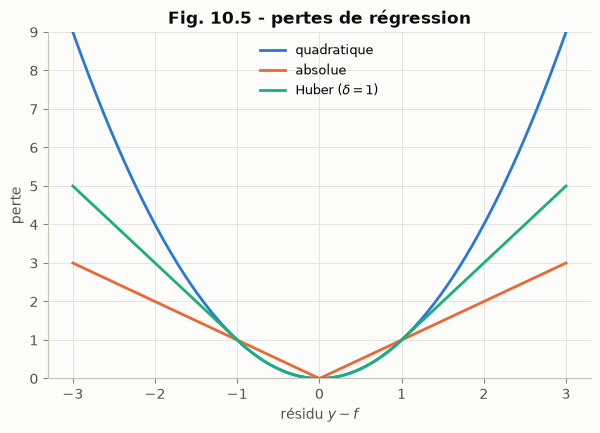

In [5]:
r = np.linspace(-3, 3, 301)
plt.figure(figsize=(7, 4.5))
plt.plot(r, r ** 2, color=COLORS[0], label="quadratique")
plt.plot(r, np.abs(r), color=COLORS[1], label="absolue")
plt.plot(r, loss_huber(r, 1.0), color=COLORS[2], label="Huber ($\\delta = 1$)")
plt.ylim(0, 9)
plt.title("Fig. 10.5 - pertes de régression")
plt.xlabel("résidu $y - f$")
plt.ylabel("perte")
plt.legend()
plt.show()

## 3. Boosting d'arbres

Un arbre de régression ou de classification (chapitre 9) découpe l'espace des
prédicteurs en régions disjointes $R_1,\dots,R_J$ (les feuilles) et prédit une constante
$\gamma_j$ dans chacune :

$$T(x;\Theta) = \sum_{j=1}^J \gamma_j\, I(x \in R_j) \qquad \text{(éq. (10.25))},\qquad \Theta = \{R_j, \gamma_j\}_{1}^{J}.$$

Un modèle d'**arbres boostés** est une somme d'arbres $f_M(x) = \sum_{m=1}^M T(x;\Theta_m)$
(éq. (10.28)), construite pas à pas (algorithme 10.2) : à l'étape $m$,

$$\hat\Theta_m = \arg\min_{\Theta_m}\sum_{i=1}^N L\big(y_i, f_{m-1}(x_i) + T(x_i;\Theta_m)\big) \qquad \text{(éq. (10.29))}.$$

Ce problème se découpe en deux :

- **régions connues** : trouver les constantes est facile, feuille par feuille,
  $$\hat\gamma_{jm} = \arg\min_{\gamma}\sum_{x_i\in R_{jm}} L\big(y_i, f_{m-1}(x_i) + \gamma\big) \qquad \text{(éq. (10.30))} ;$$
- **trouver les régions** est difficile pour une perte quelconque. Pour la perte quadratique,
  c'est simplement l'arbre de régression qui prédit au mieux les résidus ; pour la perte
  exponentielle, on retrouve AdaBoost (avec des arbres « signe » mis à l'échelle). Pour la
  perte absolue, Huber ou la déviance, il faut une autre idée : le **gradient**.

## 4. Gradient boosting

### Descente de gradient dans l'espace des prédictions

Oublions un instant les arbres et voyons la perte d'apprentissage comme une fonction du
vecteur des prédictions $\mathbf f = (f(x_1),\dots,f(x_N)) \in \mathbb R^N$ :

$$L(\mathbf f) = \sum_{i=1}^N L\big(y_i, f(x_i)\big) \qquad \text{(éq. (10.33))}.$$

Une **descente de gradient** part de $\mathbf f_0$ et fait des pas
$\mathbf f_m = \mathbf f_{m-1} - \rho_m \mathbf g_m$, où

$$g_{im} = \left[\frac{\partial L(y_i, f(x_i))}{\partial f(x_i)}\right]_{f = f_{m-1}} \qquad \text{(éq. (10.35))}$$

et $\rho_m$ est choisi par recherche linéaire (éq. (10.36)). Chaque composante du gradient
ne dépend que de l'observation $i$ : la direction $-\mathbf g_m$ est facile à calculer.

**Problème :** $-\mathbf g_m$ n'est défini qu'aux points d'apprentissage ; il ne fournit
pas de prédiction pour un nouveau $x$. **Solution :** on ajuste un arbre de régression à
$-\mathbf g_m$ par moindres carrés,

$$\tilde\Theta_m = \arg\min_{\Theta}\sum_{i=1}^N\big(-g_{im} - T(x_i;\Theta)\big)^2 \qquad \text{(éq. (10.37))},$$

c'est-à-dire l'arbre le plus « parallèle » possible au gradient négatif. Les régions de
cet arbre servent ensuite dans (10.30) pour calculer les constantes des feuilles.

### Tableau 10.2 - gradients usuels

| cadre | perte $L(y,f)$ | $-\partial L/\partial f$ (« pseudo-résidu ») |
|---|---|---|
| régression | $\frac12(y-f)^2$ | $y - f$ |
| régression | $\lvert y-f\rvert$ | $\operatorname{signe}(y-f)$ |
| régression | Huber | $y-f$ si $\lvert y-f\rvert\le\delta_m$, sinon $\delta_m\operatorname{signe}(y-f)$ |
| classification | déviance | composante $k$ : $I(y = G_k) - p_k(x)$ |

Pour Huber, $\delta_m$ est le quantile d'ordre $\alpha$ (ici $0{,}9$) des $|y_i - f_{m-1}(x_i)|$.
Pour la déviance binomiale avec $y\in\{0,1\}$ et $f$ = log-rapport de cotes,
$L = \log(1+e^{f}) - yf$ et $-\partial L/\partial f = y - p(x)$.

### Algorithme 10.3 - gradient boosting d'arbres (reformulé)

1. $f_0(x) = \arg\min_\gamma\sum_i L(y_i,\gamma)$ (moyenne, médiane, log-cote empirique…).
2. Pour $m = 1,\dots,M$ :
   1. pseudo-résidus $r_{im} = -\big[\partial L(y_i,f(x_i))/\partial f(x_i)\big]_{f=f_{m-1}}$ ;
   2. ajuster un arbre de régression à $J$ feuilles aux $r_{im}$ : régions $R_{jm}$ ;
   3. pour chaque feuille, $\gamma_{jm} = \arg\min_\gamma\sum_{x_i\in R_{jm}} L(y_i, f_{m-1}(x_i)+\gamma)$ ;
   4. $f_m(x) = f_{m-1}(x) + \sum_j \gamma_{jm} I(x\in R_{jm})$.
3. Renvoyer $\hat f = f_M$.

Dans notre module (`GradientBoosting`), l'étape 2.3 est exacte pour les pertes quadratique
(moyenne des résidus) et absolue (médiane des résidus), approchée par un pas de Newton
pour la déviance ($\sum r_i / \sum p_i(1-p_i)$, borné à $\pm 4$ pour éviter qu'une feuille ne
contenant que des points très mal classés avec $p_i(1-p_i)\approx 0$ reçoive une valeur
démesurée) et par l'approximation de Friedman pour Huber.

### Expérience : régression avec valeurs aberrantes

On simule $y = \sin(2\pi x_1) + 2x_2^2 + \varepsilon$ avec $\varepsilon\sim\mathcal N(0, 0{,}3^2)$, puis on
remplace 10 % des réponses d'apprentissage par des valeurs aberrantes (décalage de $+8$ en
moyenne). On compare le gradient boosting avec les trois pertes, en mesurant l'erreur par
rapport à la vraie fonction sur un échantillon de test **propre**.

In [6]:
rng = np.random.RandomState(1)
def f_true(Z):
    return np.sin(2 * np.pi * Z[:, 0]) + 2 * Z[:, 1] ** 2
Xr = rng.rand(1000, 4)
yr = f_true(Xr) + 0.3 * rng.randn(1000)
out = rng.rand(1000) < 0.1
yr[out] += 8 + 2 * rng.randn(out.sum())
Xr_test = rng.rand(5000, 4)
fr_test = f_true(Xr_test)

In [7]:
models_r = {}
for loss in ("ls", "lad", "huber"):
    models_r[loss] = GradientBoosting(loss, 300, 4, learning_rate=0.1).fit(Xr, yr)
curves_r = {}
for loss, gb in models_r.items():
    curves_r[loss] = [np.mean((f - fr_test) ** 2) for f in gb.staged_decision_function(Xr_test)]
    print("%-6s : erreur quadratique vs f vraie après 300 arbres = %.3f" % (loss, curves_r[loss][-1]))

ls     : erreur quadratique vs f vraie après 300 arbres = 1.521
lad    : erreur quadratique vs f vraie après 300 arbres = 0.126
huber  : erreur quadratique vs f vraie après 300 arbres = 0.601


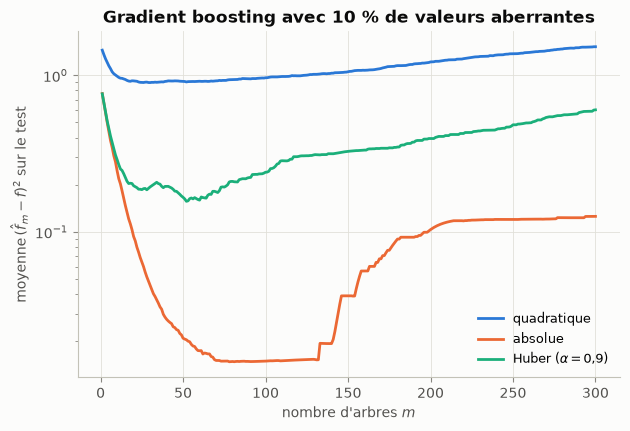

In [8]:
labels = {"ls": "quadratique", "lad": "absolue", "huber": "Huber ($\\alpha=0{,}9$)"}
plt.figure(figsize=(7, 4.5))
for k, (loss, c) in enumerate(curves_r.items()):
    plt.plot(np.arange(1, 301), c, color=COLORS[k], label=labels[loss])
plt.yscale("log")
plt.title("Gradient boosting avec 10 % de valeurs aberrantes")
plt.xlabel("nombre d'arbres $m$")
plt.ylabel("$\\mathrm{moyenne}\\,(\\hat f_m - f)^2$ sur le test")
plt.legend()
plt.show()

La perte quadratique est entraînée par les valeurs aberrantes (elle estime la moyenne
conditionnelle de données contaminées, décalée vers le haut). Les pertes absolue et de
Huber, qui ne donnent qu'une influence **bornée** à chaque résidu, retrouvent beaucoup
mieux la vraie fonction. La perte de Huber est ici moins bonne que la perte absolue :
avec $\alpha = 0{,}9$, le seuil $\delta_m$ est le quantile à 90 % des résidus absolus, si bien
qu'avec 10 % de valeurs aberrantes une partie d'entre elles reste dans la zone quadratique.
Un $\alpha$ plus petit (par exemple $0{,}8$) la rendrait plus robuste ; en contrepartie, la
perte de Huber est plus efficace que la perte absolue lorsque les erreurs sont gaussiennes.

## 5. Taille des arbres et interactions

Quelle taille $J$ choisir pour les arbres ? Le livre recommande d'utiliser la **même** taille
pour tous les arbres et de la voir comme un méta-paramètre. Pour guider ce choix,
décomposons la fonction cible $\eta$ (le minimiseur du risque, éq. (10.39)) en
**ANOVA** :

$$\eta(X) = \sum_j \eta_j(X_j) + \sum_{j<k}\eta_{jk}(X_j,X_k) + \sum_{j<k<l}\eta_{jkl}(X_j,X_k,X_l) + \cdots \qquad \text{(éq. (10.40))}.$$

Les $\eta_j$ sont les **effets principaux**, les $\eta_{jk}$ les **interactions d'ordre 2**, etc.

> **Intuition.** Un arbre à $J$ feuilles a $J-1$ coupures : une feuille est définie par au
> plus $J-1$ variables, donc l'arbre ne peut pas créer d'interaction d'ordre supérieur à
> $J-1$. Une somme d'arbres non plus. Des souches ($J=2$) donnent un **modèle additif** (effets
> principaux seulement) ; $J = 3$ permet des interactions d'ordre 2, etc. En pratique,
> $4 \le J \le 8$ convient presque toujours, et $J\approx 6$ est un bon défaut.

### Figure 10.9 : souches, arbres à 10 et 100 feuilles

Pour la simulation (10.2), le log-rapport de cotes est une fonction (dégénérée) de
$\sum_j X_j^2$, somme de fonctions d'une seule variable : le modèle est **additif**. Les souches
devraient donc être idéales. On utilise la déviance binomiale sans rétrécissement.

In [9]:
rng = np.random.RandomState(0)
X, y = simulate_nested_spheres(2000, rng=rng)
Xt, yt = simulate_nested_spheres(10000, rng=rng)
y01, yt01 = (y + 1) // 2, (yt + 1) // 2

In [10]:
M9 = 400
res9 = {}
for J in (2, 10, 100):
    gb = GradientBoosting("deviance", M9, J, learning_rate=1.0).fit(X, y01)
    _, _, err = gb.staged_scores(Xt, yt01)
    res9[J] = err
ada9 = AdaBoostM1(M9, 2).fit(X, y).staged_errors(Xt, yt)

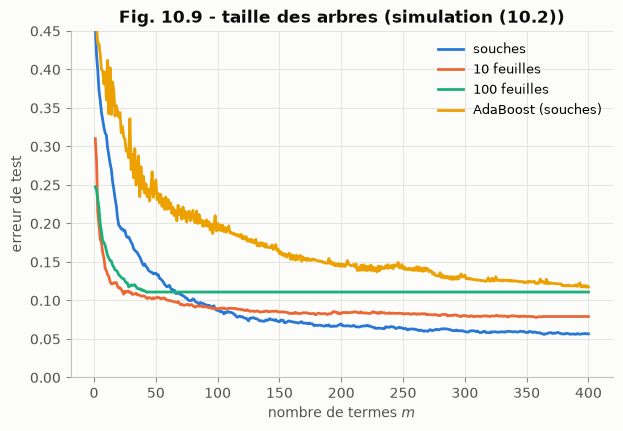

J =   2 : erreur de test minimale = 0.056
J =  10 : erreur de test minimale = 0.078
J = 100 : erreur de test minimale = 0.111


In [11]:
plt.figure(figsize=(7, 4.5))
it9 = np.arange(1, M9 + 1)
for k, J in enumerate(res9):
    lab = "souches" if J == 2 else "%d feuilles" % J
    plt.plot(it9, res9[J], color=COLORS[k], label=lab)
plt.plot(it9, ada9, color=COLORS[3], label="AdaBoost (souches)")
plt.ylim(0, 0.45)
plt.title("Fig. 10.9 - taille des arbres (simulation (10.2))")
plt.xlabel("nombre de termes $m$")
plt.ylabel("erreur de test")
plt.legend()
plt.show()
for J in res9:
    print("J = %3d : erreur de test minimale = %.3f" % (J, res9[J].min()))

Comme dans le livre, les souches gagnent : des arbres plus grands introduisent des
interactions inutiles, donc de la variance supplémentaire, sans réduire le biais.

### Figure 10.10 : fonctions de coordonnées

Avec des souches, chaque arbre ne dépend que d'une variable : en regroupant les souches
selon leur variable de coupure, on obtient
$\hat f(x) = \hat f_0 + \sum_{j=1}^{10} \hat f_j(x_j)$. Comparons chaque $\hat f_j$ (centrée)
à la fonction « vraie » $x_j^2$, à un facteur d'échelle près (le vrai log-rapport de cotes
est infini puisque les classes sont séparées : seule la forme compte).

In [12]:
gb_st = GradientBoosting("deviance", M9, 2, learning_rate=1.0).fit(X, y01)
xg = np.linspace(-2.5, 2.5, 201)
coord = np.zeros((10, xg.size))
for t in gb_st.trees_:
    j = t.feature[0]
    if j < 0:
        continue
    Z = np.zeros((xg.size, 10))
    Z[:, j] = xg
    coord[j] += t.predict(Z)
dens = np.exp(-xg ** 2 / 2)                    # centrage pondéré par la loi de X_j
coord -= (coord * dens).sum(1, keepdims=True) / dens.sum()
q = xg ** 2 - (xg ** 2 * dens).sum() / dens.sum()
scale = (coord @ q).sum() / (10 * q @ q)      # facteur d'échelle commun (moindres carrés)

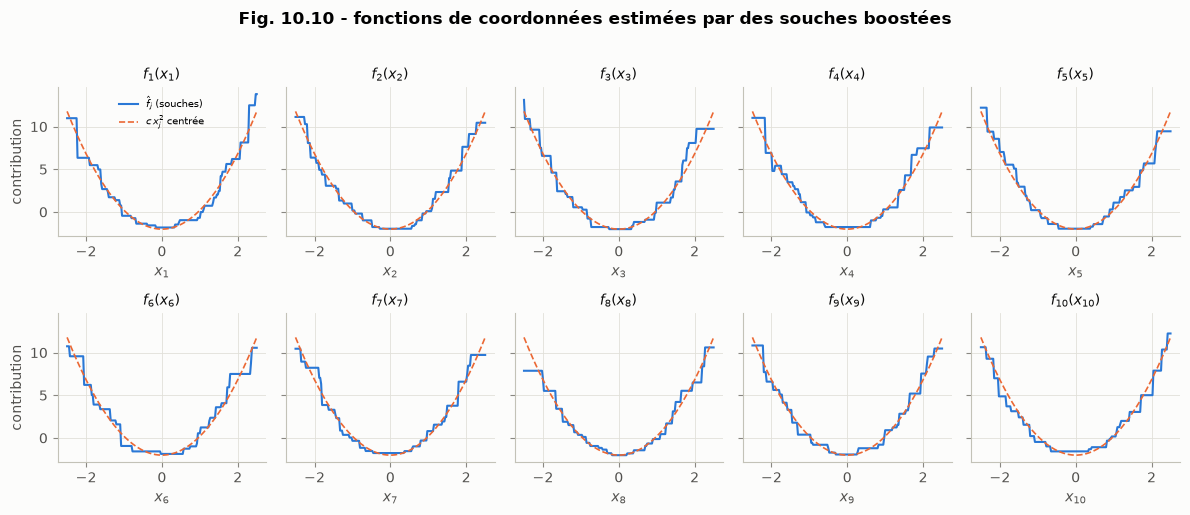

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5), sharey=True)
for j, ax in enumerate(axes.ravel()):
    ax.plot(xg, coord[j], color=BLUE, lw=1.5, label="$\\hat f_j$ (souches)")
    ax.plot(xg, scale * q, color=ORANGE, ls="--", lw=1.2, label="$c\\,x_j^2$ centrée")
    ax.set_title("$f_{%d}(x_{%d})$" % (j + 1, j + 1), fontsize=10)
    ax.set_xlabel("$x_{%d}$" % (j + 1))
axes[0, 0].set_ylabel("contribution")
axes[1, 0].set_ylabel("contribution")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Fig. 10.10 - fonctions de coordonnées estimées par des souches boostées",
             fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Chaque fonction de coordonnée estimée a bien la forme quadratique attendue : le boosting
de souches a « découvert » la structure additive du problème.

## 6. Régularisation

Le nombre d'itérations $M$ est un premier paramètre de régularisation : la perte
d'apprentissage peut être rendue arbitrairement petite, mais un $M$ trop grand surajuste.
On choisit $M$ sur un échantillon de validation (arrêt précoce, comme pour les réseaux
de neurones).

### Rétrécissement (*shrinkage*)

On multiplie la contribution de chaque arbre par $0 < \nu \le 1$ :

$$f_m(x) = f_{m-1}(x) + \nu\sum_{j=1}^J \gamma_{jm} I(x\in R_{jm}) \qquad \text{(éq. (10.41))}.$$

Plus $\nu$ est petit, plus il faut d'itérations pour un même risque d'apprentissage. La
règle empirique (Friedman, 2001) : prendre $\nu$ **petit** ($\nu < 0{,}1$) et choisir $M$ par
arrêt précoce.

### Figure 10.11 : effet du rétrécissement

Simulation (10.2), déviance binomiale, souches ($\nu = 1$ ou $0{,}2$) et arbres à 6 feuilles,
2000 itérations. On suit la déviance de test et l'erreur de test. Pour les arbres à 6
feuilles, le livre compare $\nu = 1$ et $\nu = 0{,}6$ ; avec notre implémentation, $\nu = 0{,}6$ se
comporte presque comme $\nu = 1$, et nous montrons plutôt un rétrécissement plus fort, $\nu = 0{,}1$.

In [14]:
M11 = 2000
configs11 = [(2, 1.0), (2, 0.2), (6, 1.0), (6, 0.1)]
res11 = {}
for J, nu in configs11:
    gb = GradientBoosting("deviance", M11, J, learning_rate=nu).fit(X, y01)
    res11[(J, nu)] = gb.staged_scores(Xt, yt01, every=10)

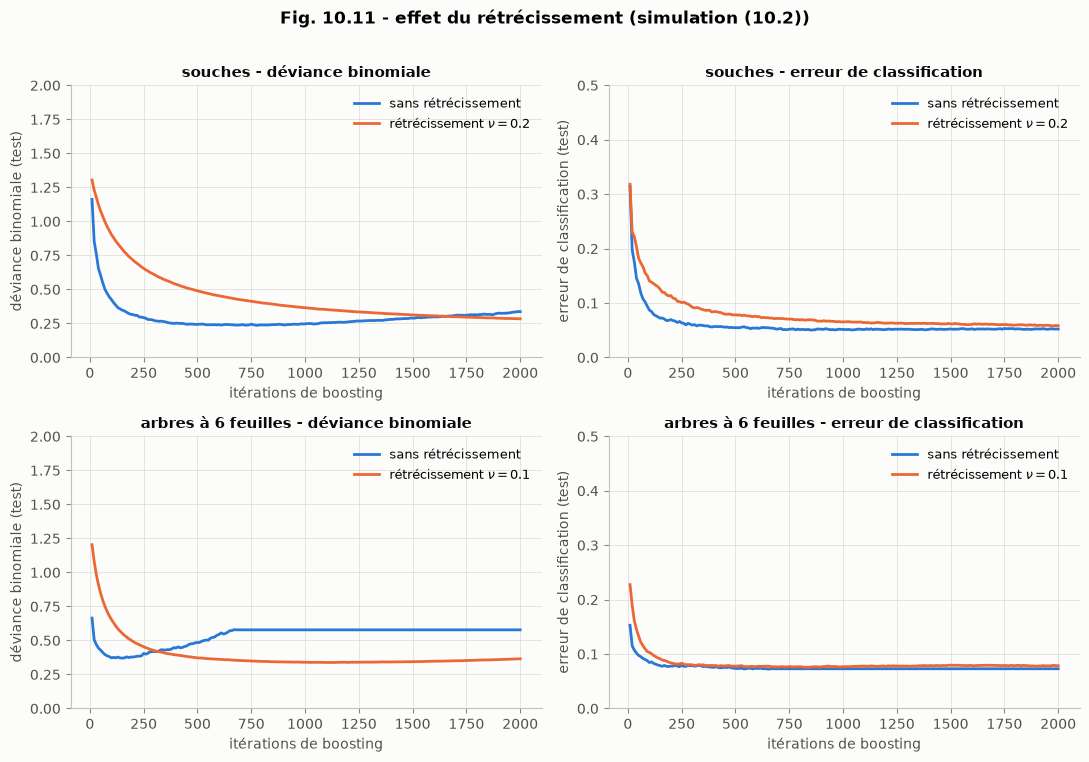

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, J in enumerate((2, 6)):
    for col, (key, name) in enumerate(((1, "déviance binomiale"), (2, "erreur de classification"))):
        ax = axes[row, col]
        for k, nu in enumerate([c[1] for c in configs11 if c[0] == J]):
            its, dev, err = res11[(J, nu)]
            vals = dev if key == 1 else err
            lab = "sans rétrécissement" if nu == 1 else "rétrécissement $\\nu = %.1f$" % nu
            ax.plot(its, vals, color=COLORS[k], label=lab)
        ax.set_ylim(0, 2.0 if key == 1 else 0.5)
        ax.set_title("%s - %s" % ("souches" if J == 2 else "arbres à 6 feuilles", name), fontsize=11)
        ax.set_xlabel("itérations de boosting")
        ax.set_ylabel("%s (test)" % name)
        ax.legend()
fig.suptitle("Fig. 10.11 - effet du rétrécissement (simulation (10.2))", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [16]:
for (J, nu), (its, dev, err) in res11.items():
    print("J = %d, nu = %.1f : déviance test min = %.3f (m = %4d), erreur test min = %.3f"
          % (J, nu, dev.min(), its[dev.argmin()], err.min()))

J = 2, nu = 1.0 : déviance test min = 0.236 (m =  780), erreur test min = 0.050
J = 2, nu = 0.2 : déviance test min = 0.284 (m = 2000), erreur test min = 0.058
J = 6, nu = 1.0 : déviance test min = 0.370 (m =  150), erreur test min = 0.072
J = 6, nu = 0.1 : déviance test min = 0.338 (m = 1130), erreur test min = 0.076


Sans rétrécissement, la déviance de test atteint vite un minimum puis **remonte** : le
modèle devient trop sûr de lui (probabilités poussées vers 0 ou 1 ; avec des arbres à 6
feuilles, l'échantillon d'apprentissage est vite parfaitement séparé, les pseudo-résidus
s'annulent et la courbe se fige à un niveau élevé). Avec rétrécissement, la courbe
descend plus lentement mais **reste basse** beaucoup plus longtemps : le choix de $M$
devient bien moins critique. Sur notre réalisation, le gain sur le minimum lui-même est
modeste (il est plus marqué dans le livre), et l'effet sur l'erreur de classification
est faible : c'est surtout l'**estimation des probabilités** qui profite du rétrécissement.

### Sous-échantillonnage : gradient boosting stochastique

Inspiré du *bagging* (section 8.7), le gradient boosting **stochastique** (Friedman, 1999)
tire à chaque itération une fraction $\eta$ des observations **sans remise** et construit
l'arbre sur ce sous-échantillon seulement (une valeur typique est $\eta = 1/2$). Le calcul
est accéléré d'un facteur $\eta$ et, souvent, le modèle est plus précis.

### Figure 10.12 : effet du sous-échantillonnage

Arbres à 4 feuilles, simulation (10.2), 1000 itérations, quatre réglages : sans
rétrécissement ; $\nu = 0{,}1$ ; sous-échantillon $\eta = 0{,}5$ ; $\nu = 0{,}1$ et
$\eta = 0{,}5$. À gauche, la déviance binomiale ; à droite, la perte quadratique appliquée
à $y\in\{0,1\}$ (régression), évaluée par l'erreur absolue moyenne de test.

In [17]:
M12 = 1000
configs12 = [(1.0, 1.0), (0.1, 1.0), (1.0, 0.5), (0.1, 0.5)]
res12 = {}
for loss in ("deviance", "ls"):
    for nu, eta in configs12:
        gb = GradientBoosting(loss, M12, 4, learning_rate=nu, subsample=eta,
                              random_state=0).fit(X, y01)
        if loss == "deviance":
            its, dev, _ = gb.staged_scores(Xt, yt01, every=10)
            res12[(loss, nu, eta)] = (its, dev)
        else:
            vals = [np.mean(np.abs(f - yt01)) for k, f in
                    enumerate(gb.staged_decision_function(Xt), 1) if k % 10 == 0]
            res12[(loss, nu, eta)] = (np.arange(10, M12 + 1, 10), np.array(vals))

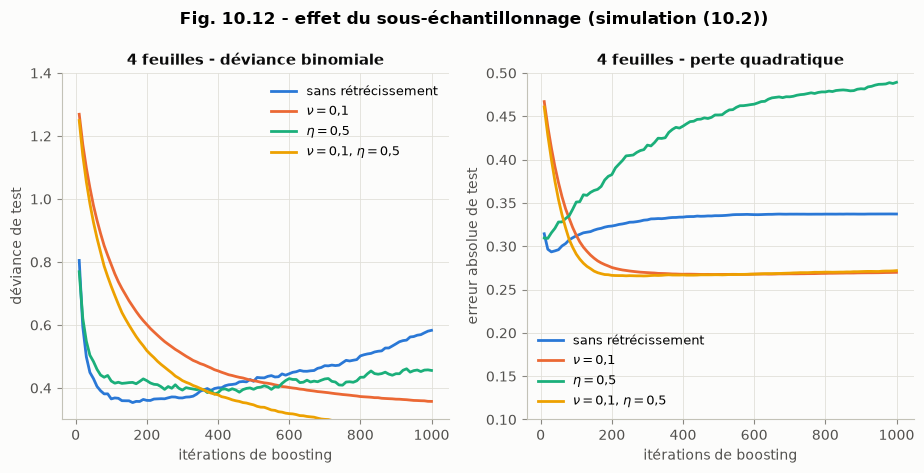

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
names = {(1.0, 1.0): "sans rétrécissement", (0.1, 1.0): "$\\nu = 0{,}1$",
         (1.0, 0.5): "$\\eta = 0{,}5$", (0.1, 0.5): "$\\nu = 0{,}1$, $\\eta = 0{,}5$"}
for ax, loss, title, ylab in ((axes[0], "deviance", "déviance binomiale", "déviance de test"),
                              (axes[1], "ls", "perte quadratique", "erreur absolue de test")):
    for k, cfg in enumerate(configs12):
        its, vals = res12[(loss,) + cfg]
        ax.plot(its, vals, color=COLORS[k], label=names[cfg])
    ax.set_title("4 feuilles - %s" % title, fontsize=11)
    ax.set_xlabel("itérations de boosting")
    ax.set_ylabel(ylab)
    ax.legend()
axes[0].set_ylim(0.3, 1.4)
axes[1].set_ylim(0.1, 0.5)
fig.suptitle("Fig. 10.12 - effet du sous-échantillonnage (simulation (10.2))", fontweight="bold", y=1.02)
plt.show()

In [19]:
for key, (its, vals) in res12.items():
    print("%-8s nu = %.1f, eta = %.1f : minimum = %.3f (m = %d)"
          % (key[0], key[1], key[2], vals.min(), its[vals.argmin()]))

deviance nu = 1.0, eta = 1.0 : minimum = 0.354 (m = 160)
deviance nu = 0.1, eta = 1.0 : minimum = 0.357 (m = 1000)
deviance nu = 1.0, eta = 0.5 : minimum = 0.381 (m = 390)
deviance nu = 0.1, eta = 0.5 : minimum = 0.273 (m = 980)
ls       nu = 1.0, eta = 1.0 : minimum = 0.294 (m = 30)
ls       nu = 0.1, eta = 1.0 : minimum = 0.267 (m = 490)
ls       nu = 1.0, eta = 0.5 : minimum = 0.309 (m = 20)
ls       nu = 0.1, eta = 0.5 : minimum = 0.266 (m = 290)


Comme dans le livre, le sous-échantillonnage **combiné** au rétrécissement donne les
meilleurs résultats, tandis que le sous-échantillonnage seul (sans rétrécissement) se
comporte mal : chaque arbre, ajusté sur la moitié des données et ajouté en entier, est
trop bruité.

## Bilan

> **À retenir.**
> - Les pertes de classification s'expriment avec la marge $yf$ ; la déviance binomiale
>   croît linéairement pour les marges négatives et résiste mieux au bruit d'étiquetage
>   que la perte exponentielle. En régression, les pertes absolue et de Huber résistent aux
>   valeurs aberrantes.
> - Le **gradient boosting** ajuste à chaque étape un arbre de moindres carrés aux
>   **pseudo-résidus** $-\partial L/\partial f$, puis optimise la constante de chaque feuille
>   pour la vraie perte : un seul algorithme pour toutes les pertes différentiables.
> - La taille $J$ des arbres borne l'ordre des interactions ($J-1$) ; $J \approx 6$ est un bon défaut.
> - Régularisation : petit **rétrécissement** $\nu$ + arrêt précoce, et **sous-échantillonnage**
>   $\eta \approx 1/2$.